# How WorldParticle simulates particles: a jelly and a sand pile in a box

This notebook builds a tiny **WorldParticle**, the model from Wang, Guo, Chen et al. 2026, *WorldParticle: Unified
World Simulation of Lagrangian Particle Dynamics via Transformer* ([arXiv:2605.15305](https://arxiv.org/abs/2605.15305)).
The paper trains one transformer architecture on six kinds of physics (fluid, cloth, sand, non-Newtonian flow,
elastic solids, proteins), all written as **particles**. Here we use two of them, in 2D and with 64 particles each, so
that every tensor fits on screen:

* a **jelly**: an 8×8 block of particles joined by springs, dropped into the box (the paper's elastic solids and
  cloth: it has a mesh **topology**, and its material attribute is the spring stiffness $k$);
* a **sand** column: 64 grains with friction and no springs, which collapses into a pile (the paper's MPM sand:
  no topology, and the attribute is the friction coefficient $\mu$).

**What is learned?** Not the whole time step, as in [GNS](../../../05-graph-neural-networks/gnn/), but only the part a
cheap integrator gets wrong. One frame forward is

$$\tilde V = V + \Delta t\, g, \qquad \tilde X = X + \tfrac{\Delta t}{2}(V + \tilde V) \qquad \text{(predictor: gravity only, no learning)}$$
$$X' = \tilde X + \Delta X, \qquad V' = \tilde V + \Delta V, \qquad (\Delta X, \Delta V) = f_\theta(\tilde X, \tilde V, \text{attributes}, \text{topology}, \text{walls})$$

and the transformer $f_\theta$ is the **corrector**. It has three stages: a local **tokenizer** (learned kernels over
neighbouring particles, walls and mesh edges, like a one-shot GNS layer), a **super-token encoder** that attends and
then merges similar tokens until 64 particles become 8 tokens (the global, coarse view, comparable to
[Transolver](../../../06-neural-operators/transolver/)'s slices), and a **decoder** in which every particle queries
the super tokens.

Contents:

1. the ground truth: two small simulators;
2. what goes in, what comes out;
3. the predictor, and what is left for the network;
4. the architecture with every shape;
5. one forward pass, tensor by tensor: kernels, branches, tokens, **token merging**, cross-attention, head;
6. the rollout loss and training;
7. results on the jelly, against the ground truth and the predictor alone;
8. what it learned: are the super tokens physical, and are they stable over time?
9. generalization: stiffness outside the training range, and 100 particles instead of 64;
10. ablation: the same model without the global stage;
11. the sand: same architecture, topology zero-filled, separate weights;
12. an interactive explorer;
13. back to the paper and the review.

Everything is pure JAX, like the rest of this repository. The whole notebook runs in about 15 minutes on a laptop
CPU, most of it training.

In [1]:
import sys
sys.path.insert(0, "..")

import time
from functools import partial
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from src import physics
from src.physics import SimParams, make_dataset, jelly_springs, boundary_samples
from src.model import (WPConfig, init_params, count_params, step_with_trace, kernel_weights, predictor, rollout,
                       merge_tokens)
from src.training import fit_norm, stack_scenes, make_scene, residuals, train, rollout_errors, batch_loss
from src import visualize as viz

plt.rcParams["figure.dpi"] = 90
print("JAX", jax.__version__, "on", jax.devices()[0].platform)

JAX 0.12.0.1 on cpu


## 1. The ground truth: a jelly and a sand column

[`src/physics.py`](../src/physics.py) holds two small classical simulators, playing the role of the paper's DFSPH,
GIPC, MPM, VBD and OpenMM. Both live in the unit box with gravity $g = 3$ pointing down, and both integrate with
semi-implicit Euler in **10 small substeps per saved frame** ($\Delta t = 0.005$ per frame, 240 frames per sequence).

* **Jelly.** Springs along the 8×8 lattice and its diagonals, $F = k(|d| - L)\,\hat d$ plus damping along the spring.
  The stiffness $k$ is drawn per sequence from $[4000, 12000]$. Each sequence starts from a random height, tilt and
  sideways throw.
* **Sand.** Grains of radius $r = 0.025$ that push apart when they overlap and rub with Coulomb friction
  $|F_t| \le \mu F_n$. The friction $\mu$ is drawn per sequence from $[0.1, 0.9]$. Each sequence starts as a tall
  column with a random sideways shove.

Walls push back on any particle closer than $r$ (with friction). 100 training and 16 test sequences per category.

simulated 2 x 116 sequences of 240 frames in 23.6 s
jelly X: (100, 240, 64, 2)   (sequences, frames, particles, xy)


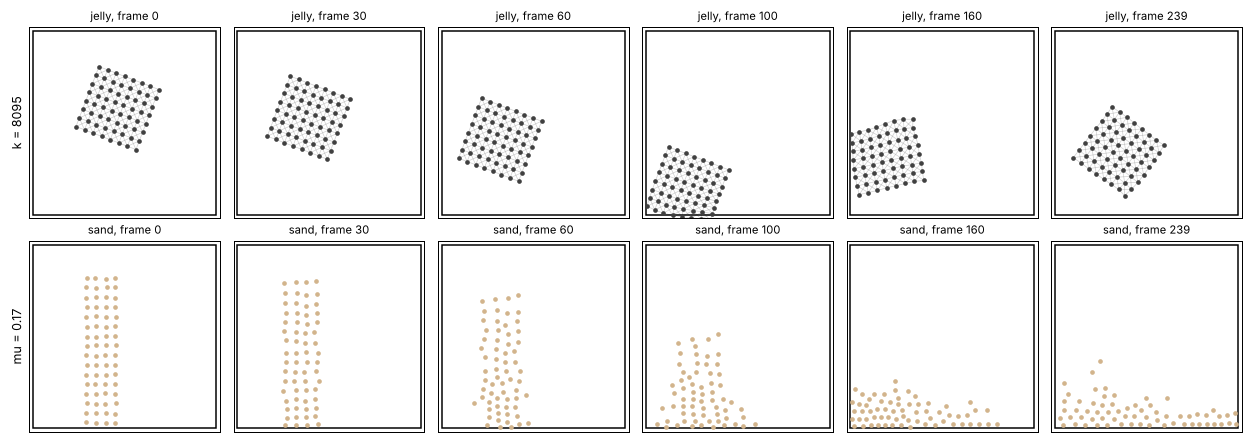

In [2]:
phys = SimParams()
t0 = time.time()
jelly_tr = make_dataset("jelly", 100, seed=0, p=phys)
jelly_te = make_dataset("jelly", 16, seed=1, p=phys)
sand_tr = make_dataset("sand", 100, seed=2, p=phys)
sand_te = make_dataset("sand", 16, seed=3, p=phys)
print(f"simulated 2 x 116 sequences of {phys.n_frames} frames in {time.time() - t0:.1f} s")
print("jelly X:", jelly_tr["X"].shape, "  (sequences, frames, particles, xy)")

rest, edges, adjacency = jelly_springs(phys)
frames = [0, 30, 60, 100, 160, 239]
fig, axes = plt.subplots(2, len(frames), figsize=(14, 5))
for j, t in enumerate(frames):
    viz.particles(axes[0, j], jelly_te["X"][0, t], edges, c="0.25", title=f"jelly, frame {t}")
    viz.particles(axes[1, j], sand_te["X"][0, t], c="tan", title=f"sand, frame {t}")
axes[0, 0].set_ylabel(f"k = {jelly_te['material'][0]:.0f}")
axes[1, 0].set_ylabel(f"mu = {sand_te['material'][0]:.2f}")
fig.tight_layout(); plt.show()

The jelly falls, lands, bounces and wobbles; its springs (grey lines) are the topology. The sand column topples and
spreads into a low pile. How far it spreads depends on $\mu$, which section 11 uses as a test.

## 2. What goes in, what comes out

For one frame of one scene the model receives a handful of matrices. **Rows are particles** (or wall samples); the
row order does not matter except for one place (token merging pairs even with odd rows, section 5d).

| input | shape | jelly | sand |
| --- | --- | --- | --- |
| positions $X$ | $64 \times 2$ | lattice | grains |
| velocities $V$ | $64 \times 2$ | | |
| attributes $a$ | $64 \times 1$ | stiffness $k$, scaled to $[-1, 1]$ | friction $\mu$, scaled to $[-1, 1]$ |
| topology: adjacency $A$ | $64 \times 64$ | 1 where a spring joins $i$ and $j$ | **all zeros** |
| topology: rest positions $R$ | $64 \times 2$ | the undeformed lattice | **all zeros** |
| walls: sample points, normals | $84 \times 2$ each | 21 points per wall | same |

Output: $\Delta X$ and $\Delta V$, each $64 \times 2$, added to the predictor's $\tilde X$, $\tilde V$.

The sand simply has no topology, so those inputs are **zero-filled**, as in the paper. The architecture is the same
for both categories: only the data and the trained weights differ.

jelly: attr (64, 1), adjacency (64, 64), rest (64, 2), wall_pts (84, 2), wall_nrm (84, 2) | springs: 210, attribute: +0.02
sand : attr (64, 1), adjacency (64, 64), rest (64, 2), wall_pts (84, 2), wall_nrm (84, 2) | springs: 0, attribute: -0.83


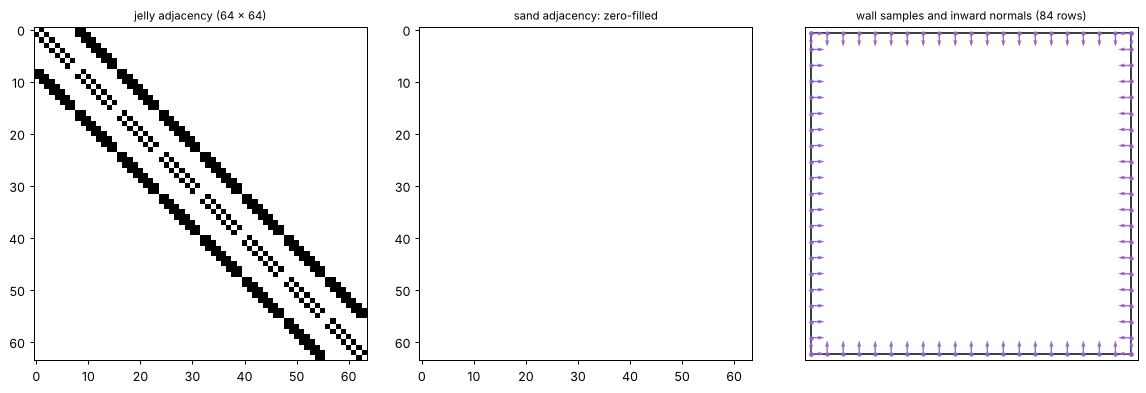

In [3]:
scene_j = make_scene("jelly", float(jelly_te["material"][0]), phys)
scene_s = make_scene("sand", float(sand_te["material"][0]), phys)
for name, sc in [("jelly", scene_j), ("sand", scene_s)]:
    print(f"{name:5s}: " + ", ".join(f"{f} {tuple(getattr(sc, f).shape)}" for f in sc._fields),
          f"| springs: {int(sc.adjacency.sum()) // 2}, attribute: {float(sc.attr[0, 0]):+.2f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
axes[0].imshow(scene_j.adjacency, cmap="Greys"); axes[0].set_title("jelly adjacency (64 x 64)", fontsize=9)
axes[1].imshow(scene_s.adjacency, cmap="Greys", vmin=0, vmax=1); axes[1].set_title("sand adjacency: zero-filled", fontsize=9)
wp, wn = boundary_samples(phys)
viz.box(axes[2], "wall samples and inward normals (84 rows)")
axes[2].quiver(wp[:, 0], wp[:, 1], wn[:, 0], wn[:, 1], scale=25, width=0.004, color="tab:purple")
axes[2].scatter(wp[:, 0], wp[:, 1], s=6, c="tab:purple")
fig.tight_layout(); plt.show()

## 3. The predictor, and what is left for the network

The predictor (paper Eq. 1) applies only the force we know for sure, gravity. Everything else is the **residual**
$\Delta X = X_{t+1} - \tilde X$, $\Delta V = V_{t+1} - \tilde V$ that the transformer must supply: springs, contacts,
friction and walls, summed over the solver's 10 substeps.

Below: how big the residual is compared with the gravity step $\Delta t\, g = 0.015$, and what happens if we roll the
predictor out alone.

jelly norm: {'v': 0.74321, 'dx': 0.000184, 'dv': 0.06687, 'dt': 0.005, 'gravity': 3.0}
sand  norm: {'v': 0.383098, 'dx': 8.5e-05, 'dv': 0.031023, 'dt': 0.005, 'gravity': 3.0}
|dV| per particle and frame: median 0.040, 99th percentile 0.311, gravity step 0.015


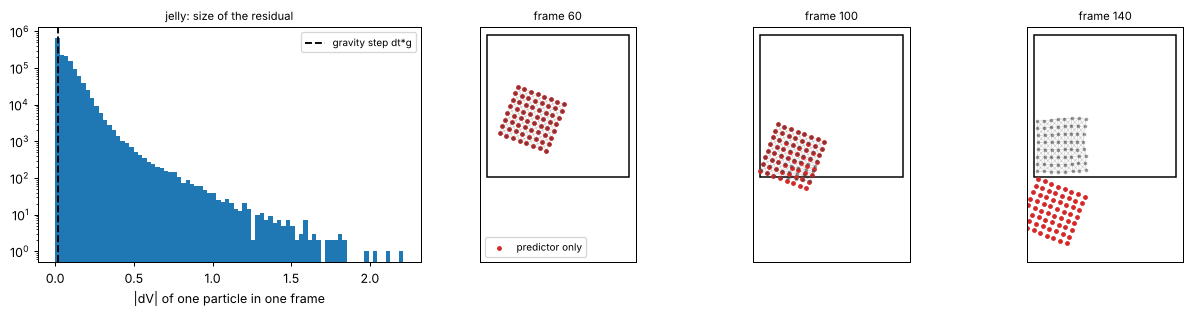

In [4]:
norm_j = fit_norm(jelly_tr, phys)
norm_s = fit_norm(sand_tr, phys)
print("jelly norm:", {k: round(float(v), 6) for k, v in norm_j._asdict().items()})
print("sand  norm:", {k: round(float(v), 6) for k, v in norm_s._asdict().items()})

dX, dV = residuals(jelly_tr["X"], jelly_tr["V"], norm_j)
speed = np.linalg.norm(dV, axis=-1).ravel()
print(f"|dV| per particle and frame: median {np.median(speed):.3f}, 99th percentile {np.percentile(speed, 99):.3f}, "
      f"gravity step {phys.frame_dt * phys.gravity:.3f}")

# The predictor alone, rolled out: nothing but gravity
x, v = jnp.asarray(jelly_te["X"][0, 0]), jnp.asarray(jelly_te["V"][0, 0])
Xp = [x]
for _ in range(phys.n_frames - 1):
    x, v = predictor(x, v, norm_j)
    Xp.append(x)
Xp = np.stack(Xp)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), gridspec_kw=dict(width_ratios=[1.4, 1, 1, 1]))
axes[0].hist(speed, bins=80, color="tab:blue", log=True)
axes[0].axvline(phys.frame_dt * phys.gravity, color="k", ls="--", label="gravity step dt*g")
axes[0].set_xlabel("|dV| of one particle in one frame"); axes[0].legend(fontsize=8)
axes[0].set_title("jelly: size of the residual", fontsize=9)
for ax, t in zip(axes[1:], [60, 100, 140]):
    viz.particles(ax, jelly_te["X"][0, t], edges, c="0.25", s=8, alpha=0.5)
    ax.scatter(Xp[t, :, 0], Xp[t, :, 1], s=8, c="tab:red", label="predictor only")
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.6, 1.05); ax.set_title(f"frame {t}", fontsize=9)
axes[1].legend(fontsize=8, loc="lower left")
fig.tight_layout(); plt.show()

Most of the time the residual is a few times the gravity step (the jelly wobbles), and at impacts it is more than
100 times larger: that is where contact and springs act. Without a corrector the jelly (red) falls straight through
the floor. Everything that keeps it in the box and holds it together has to come from $f_\theta$.

## 4. The architecture, with every shape

Paper Sec. 3, Fig. 2. $N = 64$ particles, token width $C = 32$, 4 heads, 3 encoder layers, 2 decoder layers.

| stage | what it does | shape (one scene) |
| --- | --- | --- |
| predictor | $\tilde V = V + \Delta t\, g$, $\tilde X = X + \frac{\Delta t}{2}(V + \tilde V)$ | $64 \times 2$, $64 \times 2$ |
| tokenizer: particle–particle | learnable $4 \times 4$ kernel of $d = \tilde x_j - \tilde x_i$, neighbours within $R = 0.08$ | $64 \times 16$ |
| tokenizer: particle–boundary | kernel of $x_b - \tilde x_i$, wall samples within $R = 0.06$ | $64 \times 16$ |
| tokenizer: topology | kernel of the rest offset $r_j - r_i$, mesh neighbours only | $64 \times 16$ |
| token MLP | $h_i = \mathrm{MLP}([pp_i, pb_i, topo_i, \tilde v_i, a_i])$ | $64 \times 32$ |
| encoder layer 1 | self-attention (2D RoPE), merge pairs, MLP | $64 \to 32$ tokens |
| encoder layer 2 | same | $32 \to 16$ |
| encoder layer 3 | same | $16 \to 8$ **super tokens** |
| decoder layer 1, 2 | particles cross-attend to the 8 super tokens, self-attend, MLP | $64 \times 32$ |
| head | MLP | $64 \times 4$ $= (\Delta x, \Delta v)$ |

The paper: $C = 1152$, 12 heads, 6 encoder and 8 decoder layers, a $4 \times 4 \times 4$ kernel lattice in 3D, 157M
parameters, up to about 50k particles.

kernels      6400 parameters
token_mlp    2720 parameters
encoder     25632 parameters
decoder     25792 parameters
head         2244 parameters
total       62852


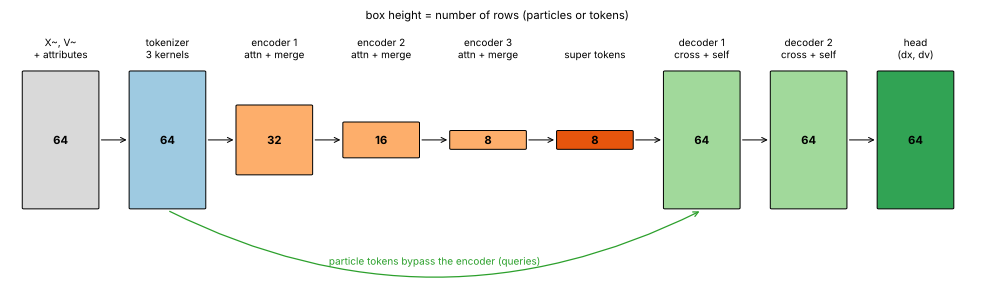

In [5]:
cfg = WPConfig()
params0 = init_params(jax.random.PRNGKey(0), cfg)
for part in ["kernels", "token_mlp", "encoder", "decoder", "head"]:
    print(f"{part:10s} {count_params(params0[part]):6d} parameters")
print(f"{'total':10s} {count_params(params0):6d}")
viz.pipeline_diagram(64, cfg); plt.show()

## 5. One forward pass, tensor by tensor

We push frame 60 of test jelly 0 through the **untrained** network `params0`. The values are random for now; the
shapes, the flow and the arithmetic are the point. Section 8 shows the trained version.

In [6]:
trace = jax.jit(step_with_trace, static_argnames=("cfg",))
seq, t_show = 0, 60
x_show, v_show = jnp.asarray(jelly_te["X"][seq, t_show]), jnp.asarray(jelly_te["V"][seq, t_show])
tr0 = trace(params0, x_show, v_show, scene_j, norm_j, cfg=cfg)
print("predictor:", tr0.x_pred.shape, tr0.v_pred.shape)
print("branches: pp", tr0.tokens["pp"].shape, " pb", tr0.tokens["pb"].shape, " topo", tr0.tokens["topo"].shape,
      " -> token h", tr0.tokens["h"].shape)
for l, L in enumerate(tr0.enc["layers"]):
    print(f"encoder {l + 1}: attention {tuple(L['attn'].shape)}, similarity {tuple(L['sim'].shape)}, "
          f"P {tuple(L['P'].shape)} -> tokens {tuple(L['x'].shape)}")
for l, L in enumerate(tr0.dec["layers"]):
    print(f"decoder {l + 1}: cross-attention {tuple(L['cross'].shape)}, self-attention {tuple(L['self'].shape)}")
print("head:", tr0.dec["out"].shape, "-> dx", tr0.dx.shape, " dv", tr0.dv.shape)

predictor: (64, 2) (64, 2)
branches: pp (64, 16)  pb (64, 16)  topo (64, 16)  -> token h (64, 32)
encoder 1: attention (4, 64, 64), similarity (32, 32), P (32, 64) -> tokens (32, 32)
encoder 2: attention (4, 32, 32), similarity (16, 16), P (16, 32) -> tokens (16, 32)
encoder 3: attention (4, 16, 16), similarity (8, 8), P (8, 16) -> tokens (8, 32)
decoder 1: cross-attention (4, 64, 8), self-attention (4, 64, 64)
decoder 2: cross-attention (4, 64, 8), self-attention (4, 64, 64)
head: (64, 4) -> dx (64, 2)  dv (64, 2)


### 5a. The continuous kernel: where a neighbour lands on the lattice

A tokenizer branch is a **continuous convolution** (as in Deep Lagrangian Fluids, which the paper cites): the
weight given to neighbour $j$ depends continuously on its offset $d = \tilde x_j - \tilde x_i$. The kernel is a
$K \times K$ lattice of weight matrices $W_{ab}$ ($C_\text{in} \times 16$ each) spread over the square $[-R, R]^2$.
The offset is mapped to lattice coordinates $s = \frac{d/R + 1}{2}(K - 1)$ and shared among the four surrounding
nodes with **bilinear** weights $\varphi_{ab}(d)$ (they sum to 1). With pair features $f_{ij}$:

$$\text{out}_i = \sum_{j:\,|d| < R} w(d)\sum_{a,b} \varphi_{ab}(d)\, f_{ij} W_{ab}, \qquad w(d) = 1 - |d|^2/R^2 .$$

So the kernel is a learned, piecewise-linear function of where the neighbour sits, the particle analogue of a CNN's
$3 \times 3$ filter. Below we do one neighbour by hand and check it against `kernel_weights`.

particle p27 has 8 neighbours within R = 0.08; take p18
d = [-0.0646 -0.0288], d/R = [-0.807 -0.36 ], lattice coordinates s = [0.289 0.96 ], window w = 0.219
phi by hand (rows a = x node, columns b = y node):
 [[0.028 0.683 0.    0.   ]
 [0.012 0.278 0.    0.   ]
 [0.    0.    0.    0.   ]
 [0.    0.    0.    0.   ]]
matches kernel_weights(): True | sums to 1.0


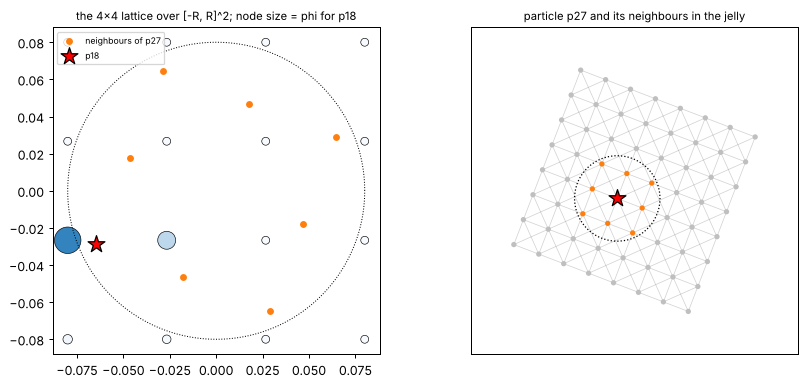

In [7]:
i = 27                                                   # a particle inside the jelly
xp = np.asarray(tr0.x_pred)
d_all = xp - xp[i]
nbrs = np.where((np.sum(d_all ** 2, 1) < cfg.r_pp ** 2) & (np.arange(64) != i))[0]
j = nbrs[0]
d = d_all[j]
K, R = cfg.kernel_size, cfg.r_pp
u = d / R
s = (u + 1) / 2 * (K - 1)
hat = np.maximum(0, 1 - np.abs(s[:, None] - np.arange(K)))          # (2, K): per axis
phi_hand = hat[0][:, None] * hat[1][None, :]
phi_code, win = kernel_weights(jnp.asarray(d), R, K)
print(f"particle p{i} has {len(nbrs)} neighbours within R = {R}; take p{j}")
print(f"d = {d.round(4)}, d/R = {u.round(3)}, lattice coordinates s = {s.round(3)}, window w = {float(win):.3f}")
print("phi by hand (rows a = x node, columns b = y node):\n", phi_hand.round(3))
print("matches kernel_weights():", np.allclose(phi_hand, np.asarray(phi_code), atol=1e-5), "| sums to", phi_hand.sum().round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
ax = axes[0]
g = np.linspace(-R, R, K)
GX, GY = np.meshgrid(g, g, indexing="ij")
ax.scatter(GX, GY, s=40 + 600 * phi_hand, c=phi_hand, cmap="Blues", vmin=0, vmax=1, ec="k", lw=0.5, zorder=2)
ax.scatter(d_all[nbrs, 0], d_all[nbrs, 1], c="tab:orange", s=20, zorder=3, label="neighbours of p%d" % i)
ax.scatter(*d, marker="*", s=200, c="red", ec="k", zorder=4, label=f"p{j}")
t = np.linspace(0, 2 * np.pi, 200)
ax.plot(R * np.cos(t), R * np.sin(t), "k:", lw=0.8)
ax.set_aspect("equal"); ax.legend(fontsize=7, loc="upper left")
ax.set_title(f"the 4x4 lattice over [-R, R]^2; node size = phi for p{j}", fontsize=9)
viz.particles(axes[1], xp, edges, c=["tab:orange" if k in nbrs else "0.75" for k in range(64)], s=18)
axes[1].scatter(*xp[i], marker="*", s=200, c="red", ec="k", zorder=4)
viz.zoom_to(axes[1], xp)
axes[1].add_patch(plt.Circle(xp[i], R, fill=False, ls=":", ec="k"))
axes[1].set_title(f"particle p{i} and its neighbours in the jelly", fontsize=9)
fig.tight_layout(); plt.show()

### 5b. Three branches: neighbours, walls, mesh

Each branch uses the same machinery with its own kernel and its own pair features. A branch is **linear in its
features** (the kernel only weights them by position), so the features are chosen such that the forces of this world
are linear combinations of them. With $n = d/|d|$ and relative velocity $\delta v$:

* **particle–particle** $[\delta v, a_j, 1, n, n|d|/R]$: enough to express a contact push that grows as grains
  overlap, and friction from the sliding velocity;
* **particle–boundary** $[n_b, \tilde v_i, 1]$: the wall's normal and how fast the particle moves into it;
* **topology** $[n, e, e\,n, \delta v, (\delta v \cdot n)\, n, 1]$ with the stretch $e = |d|/|r_j - r_i| - 1$: a
  spring's force is $k\,e\,L\,n$ plus damping along $n$. The kernel's argument is the **rest** offset $r_j - r_i$, so
  each of the 8 spring directions of the lattice gets its own weights.

The paper does not list its pair features in this detail; these are our choice for this world. The heatmaps show
the three branch outputs for 8 particles. For the sand, the topology branch is exactly zero: no springs, no inputs.

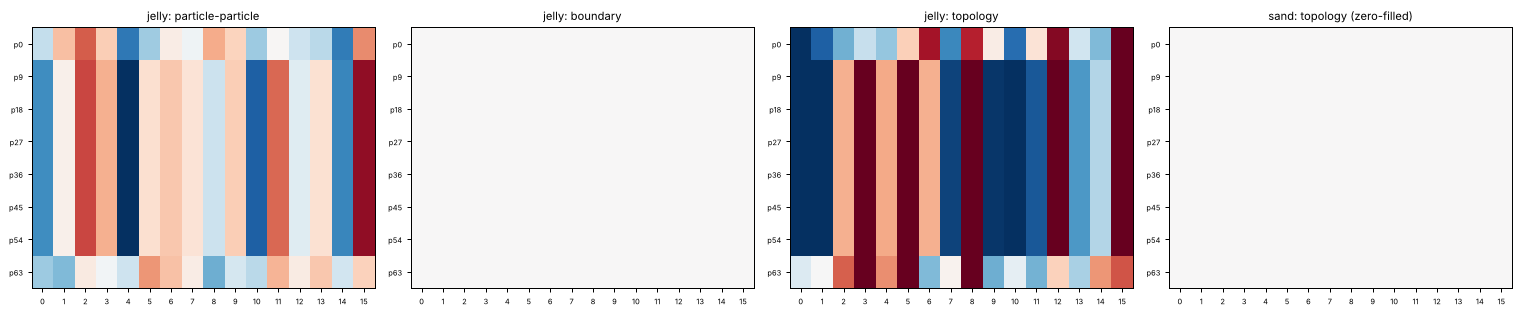

largest |sand topology| = 0.0
jelly particles touching a wall now: 0


In [8]:
rows = list(range(0, 64, 9))[:8]
trs = trace(params0, jnp.asarray(sand_te["X"][0, 60]), jnp.asarray(sand_te["V"][0, 60]), scene_s, norm_s, cfg=cfg)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
labels = [f"p{r}" for r in rows]
vmax = float(np.abs(np.asarray(tr0.tokens["pp"])[rows]).max())
for ax, (name, T) in zip(axes, [("jelly: particle-particle", tr0.tokens["pp"]), ("jelly: boundary", tr0.tokens["pb"]),
                                ("jelly: topology", tr0.tokens["topo"]), ("sand: topology (zero-filled)", trs.tokens["topo"])]):
    viz.matrix(ax, np.asarray(T)[rows], labels, None, name, annotate=False, vmax=max(vmax, 1e-3))
fig.tight_layout(); plt.show()
print("largest |sand topology| =", float(np.abs(trs.tokens["topo"]).max()))
print("jelly particles touching a wall now:", int((np.abs(np.asarray(tr0.tokens['pb'])).sum(1) > 0).sum()))

### 5c. The particle token

The three branch outputs ($3 \times 16$), the particle's own scaled velocity (2) and its attribute (1) are concatenated
($51$ numbers) and an MLP maps them to the token $h_i$ of width 32. From here on, a particle *is* this row.

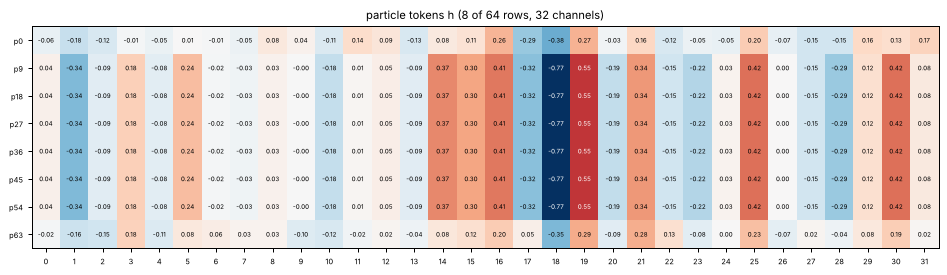

In [9]:
fig, ax = plt.subplots(figsize=(13, 3.2))
viz.matrix(ax, np.asarray(tr0.tokens["h"])[rows], labels, None, "particle tokens h (8 of 64 rows, 32 channels)",
           annotate=True, fontsize=5)
plt.show()

### 5d. Encoder layer 1: attend, then merge

Each encoder layer first runs ordinary multi-head **self-attention** among the tokens, with **2D RoPE**: queries and
keys are rotated by angles proportional to the token's $x$ and $y$, so the attention score between two tokens depends
on their *relative* position. Then comes the new part, **bipartite token merging** (borrowed from ToMe, Bolya et al.
2022):

1. split the tokens into set A (even rows) and set B (odd rows);
2. compute the cosine similarity of every A token with every B token ($32 \times 32$);
3. pair them one-to-one, greedily: A tokens with the most confident best match pick first, each takes its most
   similar B token that is still free;
4. replace each pair by its **multiplicity-weighted average** (features *and* positions); multiplicities add.

So 64 tokens become 32. The paper attends *before* merging so that similarity reflects global context, not only the
local token. The pairing is an argmax and has no gradient; the averaged values do.

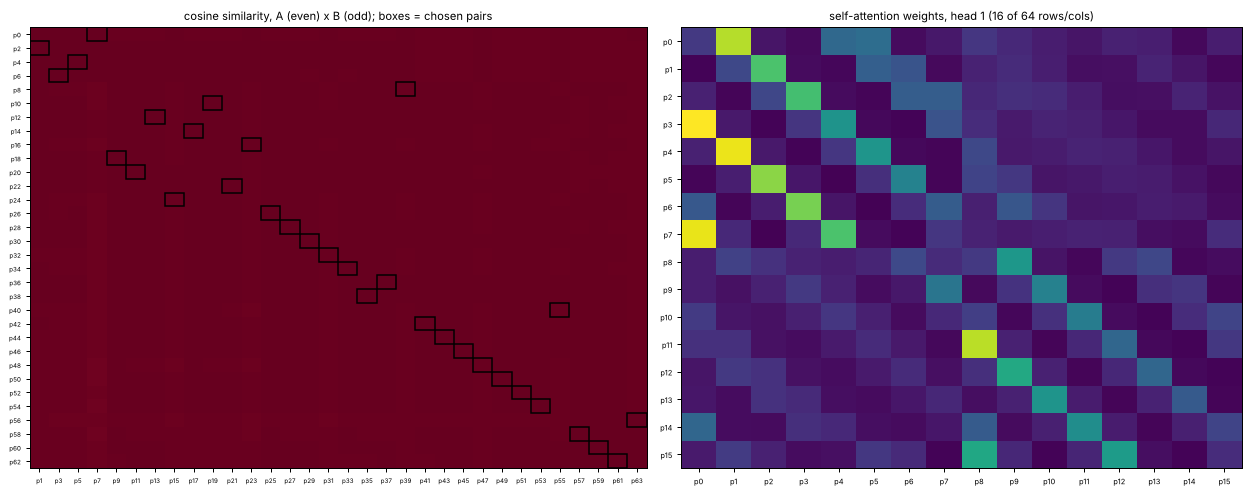

A token p10 is paired with B token p19: cosine similarity 1.000 (its best possible was 1.000)
row 5 of P: weight 0.50 on p10 and 0.50 on p19 (both had multiplicity 1)
merged position by hand [0.205  0.3918]  vs  code [0.205  0.3918]
every B token used exactly once: True


In [10]:
L1 = tr0.enc["layers"][0]
sim, match = np.asarray(L1["sim"]), np.asarray(L1["match"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw=dict(width_ratios=[1.1, 1]))
viz.matrix(axes[0], sim, [f"p{2 * a}" for a in range(32)], [f"p{2 * b + 1}" for b in range(32)],
           "cosine similarity, A (even) x B (odd); boxes = chosen pairs", annotate=False, vmax=1)
for a, b in enumerate(match):
    axes[0].add_patch(plt.Rectangle((b - 0.5, a - 0.5), 1, 1, fill=False, ec="k", lw=1.2))
axes[0].tick_params(labelsize=5)
viz.matrix(axes[1], np.asarray(L1["attn"])[0, :16, :16], [f"p{k}" for k in range(16)], [f"p{k}" for k in range(16)],
           "self-attention weights, head 1 (16 of 64 rows/cols)", cmap="viridis", annotate=False)
fig.tight_layout(); plt.show()

a = 5
b = int(match[a])
xa_, xb_ = 2 * a, 2 * b + 1
P = np.asarray(L1["P"])
print(f"A token p{xa_} is paired with B token p{xb_}: cosine similarity {sim[a, b]:.3f} "
      f"(its best possible was {sim[a].max():.3f})")
print(f"row {a} of P: weight {P[a, xa_]:.2f} on p{xa_} and {P[a, xb_]:.2f} on p{xb_} (both had multiplicity 1)")
pos_hand = 0.5 * (xp[xa_] + xp[xb_])
print(f"merged position by hand {pos_hand.round(4)}  vs  code {np.asarray(L1['pos'][a]).round(4)}")
print("every B token used exactly once:", sorted(match.tolist()) == list(range(32)))

### 5e. 64 → 32 → 16 → 8: the super tokens

Repeating attend-and-merge three times leaves 8 **super tokens**. Each one is the average of the particles merged into
it, and its anchor position (black cross, sized by multiplicity) is their average position. Colour = which token a
particle has ended up in. Untrained, the grouping is driven by random features, so it is patchy; section 8 shows the
trained grouping.

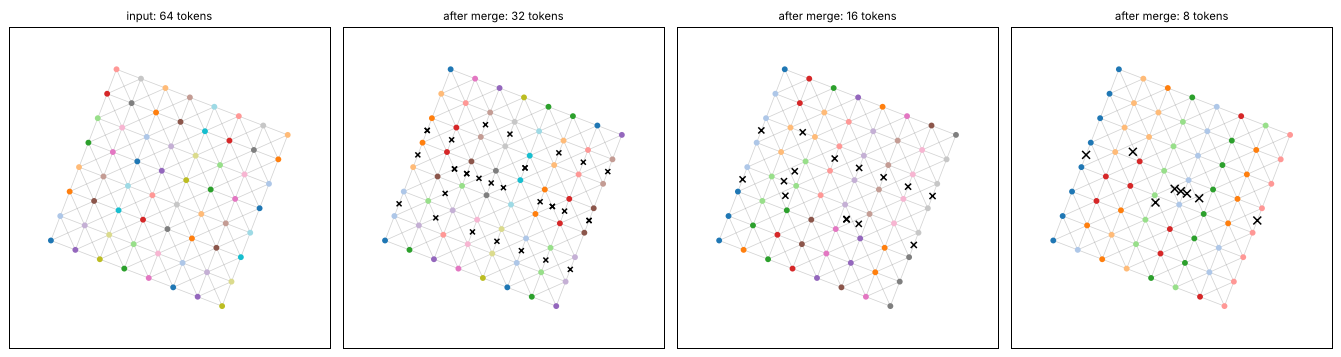

particles per super token: [8 8 8 8 8 8 8 8]


In [11]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
viz.merge_levels(axes, xp, tr0.enc["layers"], edges)
for ax in axes:
    viz.zoom_to(ax, xp)
fig.tight_layout(); plt.show()
print("particles per super token:", np.asarray(tr0.enc["z_mult"]).astype(int))

### 5f. The decoder: every particle asks the super tokens

The particle tokens $h$ skip the encoder entirely and become the decoder's **queries**. In each decoder layer:

* **cross-attention**: queries from the 64 particles, keys and values from the 8 super tokens, $64 \times 8$ weights
  per head. A particle on the bottom edge can now hear what the top of the jelly is doing in one step, where GNS
  would need several message-passing hops;
* **self-attention** among the 64 particles;
* an MLP.

The paper reads this as data-adaptive coarse-to-fine interpolation, the "deslice" of Transolver.

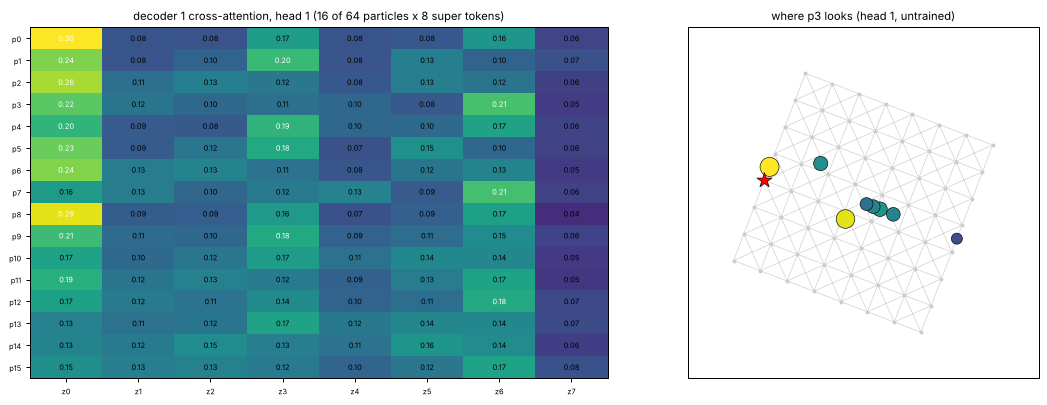

In [12]:
cross = np.asarray(tr0.dec["layers"][0]["cross"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1, 1]))
viz.matrix(axes[0], cross[0, :16], [f"p{k}" for k in range(16)], [f"z{k}" for k in range(8)],
           "decoder 1 cross-attention, head 1 (16 of 64 particles x 8 super tokens)", cmap="viridis")
viz.cross_attention(axes[1], xp, tr0.enc["z_pos"], cross[0, 3], 3, edges, "where p3 looks (head 1, untrained)")
viz.zoom_to(axes[1], xp)
fig.tight_layout(); plt.show()

### 5g. The head: corrections in physical units

A small MLP turns each particle's final row into 4 numbers, scaled by the typical residual sizes from section 3:
$\Delta x = \text{out}_{:2} \cdot s_{dx}$, $\Delta v = \text{out}_{2:} \cdot s_{dv}$. The last layer starts small, so
the untrained model is close to "no correction", that is, to the predictor.

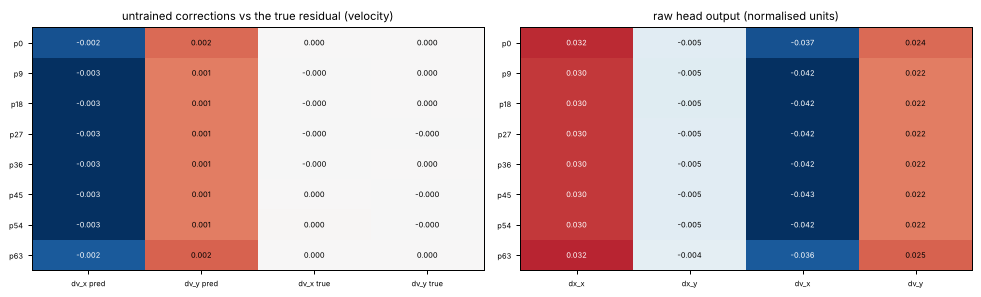

In [13]:
true_dx = np.asarray(jelly_te["X"][seq, t_show + 1]) - np.asarray(tr0.x_pred)
true_dv = np.asarray(jelly_te["V"][seq, t_show + 1]) - np.asarray(tr0.v_pred)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
viz.matrix(axes[0], np.c_[np.asarray(tr0.dv)[rows], true_dv[rows]], labels, ["dv_x pred", "dv_y pred", "dv_x true", "dv_y true"],
           "untrained corrections vs the true residual (velocity)", fontsize=6)
viz.matrix(axes[1], np.asarray(tr0.dec["out"])[rows], labels, ["dx_x", "dx_y", "dv_x", "dv_y"], "raw head output (normalised units)")
fig.tight_layout(); plt.show()

## 6. Training: the rollout loss

Paper Sec. 3.4. A training example is a **window** of $W$ consecutive true frames from one sequence. The model starts
from the first frame and runs $W - 1$ steps on its *own* predictions; the loss averages the errors over those steps:

$$L_\text{roll} = \frac{1}{W - 1}\sum_{k=1}^{W-1} \left(\frac{\|\hat X_{t+k} - X_{t+k}\|^2}{s_{dx}^2} + \frac{\|\hat V_{t+k} - V_{t+k}\|^2}{s_{dv}^2}\right)$$

(mean over particles). Dividing by the typical residual sizes makes both terms about 1 for a model that predicts
nothing, so the loss reads as "errors measured in residuals". We use $W = 4$ (the paper uses up to 5) and AdamW with
warm-up and cosine decay, 2000 steps of 8 windows. This is the slowest cell (about 5 minutes on a laptop CPU).

step   500   rollout loss (train batch) = 25.2032


step  1000   rollout loss (train batch) = 2.1866


step  1500   rollout loss (train batch) = 1.0318


step  2000   rollout loss (train batch) = 0.6495
trained in 295 s


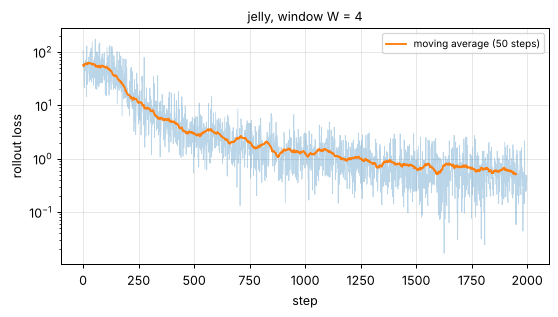

In [14]:
sc_tr_j, sc_te_j = stack_scenes("jelly", jelly_tr["material"], phys), stack_scenes("jelly", jelly_te["material"], phys)
t0 = time.time()
params_j, snaps_j, snap_steps_j, losses_j = train(params0, jelly_tr, sc_tr_j, norm_j, cfg, n_steps=2000, window=4,
                                                  batch_size=8, lr=3e-3, log_every=500)
print(f"trained in {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.semilogy(losses_j, alpha=0.3, lw=0.6)
ax.semilogy(np.convolve(losses_j, np.ones(50) / 50, mode="valid"), lw=1.5, label="moving average (50 steps)")
ax.set_xlabel("step"); ax.set_ylabel("rollout loss"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title("jelly, window W = 4", fontsize=10); plt.show()

## 7. Results on the jelly

Each test sequence is rolled out from its **first frame only**, for all 239 steps, with the model feeding on its own
output. That is much harder than the 3-step windows it was trained on. The paper's Table 1 metric is the position and
velocity MSE averaged over particles, frames and sequences; we also plot it frame by frame, which the paper does not
report.

Two references: the **predictor alone** (the corrector's weights set to zero, so only gravity acts), and frame 0
copied forever ("nothing moves").

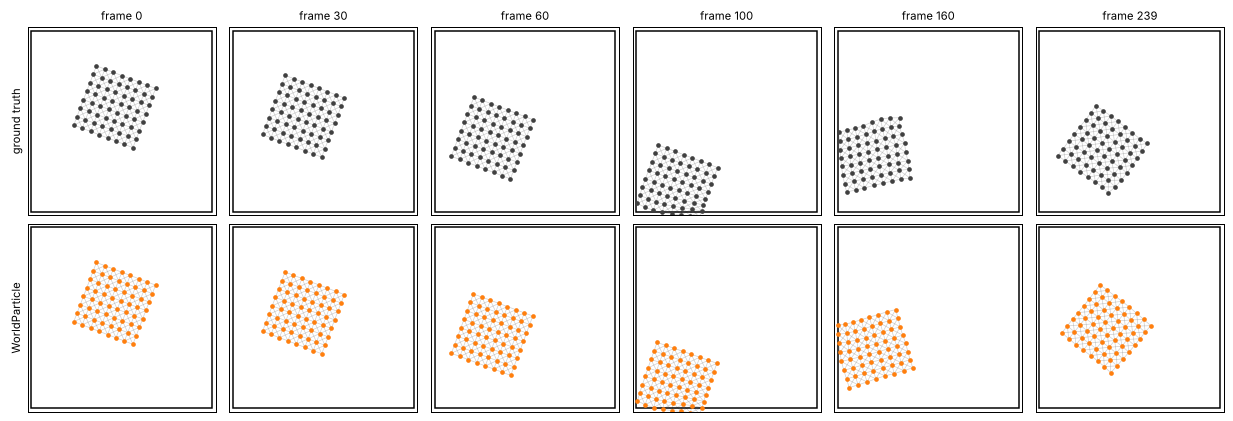

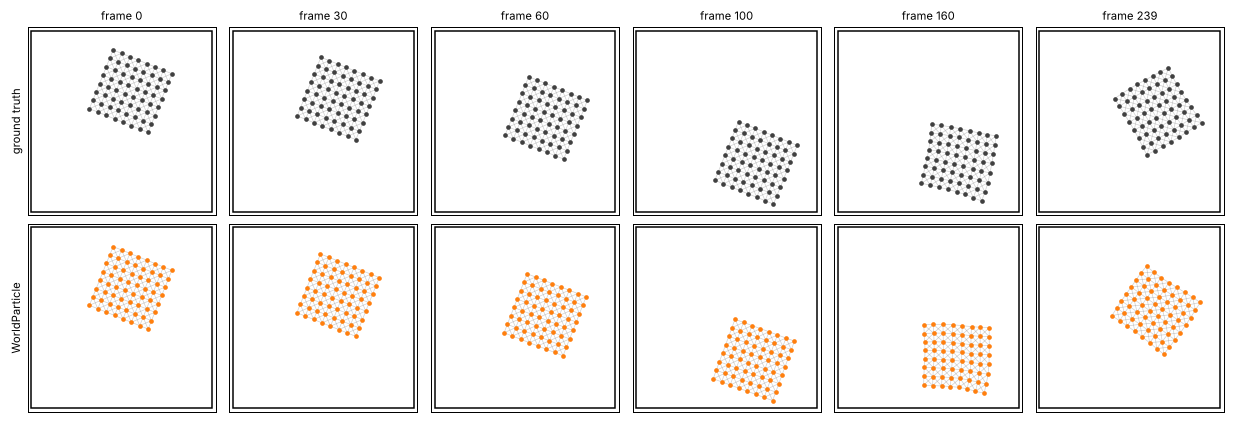

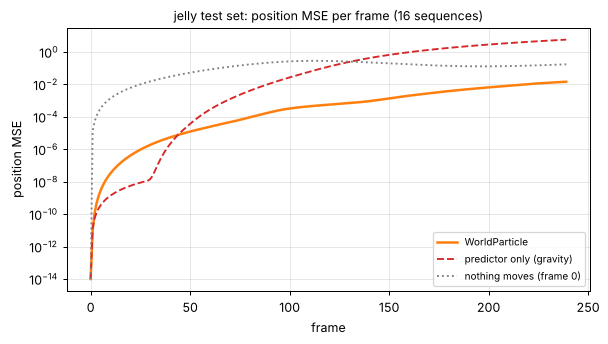

                                 pos MSE     vel MSE
WorldParticle (mean)            2.62e-03    1.02e-01
predictor only (mean)           1.09e+00    6.99e+00
WorldParticle, frame 10         3.32e-08    4.44e-05
WorldParticle, frame 50         1.24e-05    1.06e-03
WorldParticle, frame 100        3.26e-04    3.97e-02
WorldParticle, frame 239        1.46e-02    2.32e-01
speed: 674 frames/s for one 64-particle scene on this CPU


In [15]:
res_j = rollout_errors(params_j, jelly_te, sc_te_j, norm_j, cfg)
zero = jax.tree_util.tree_map(jnp.zeros_like, params_j)              # corrector outputs 0: predictor only
res_pred = rollout_errors(zero, jelly_te, sc_te_j, norm_j, cfg)
still = np.mean(np.sum((jelly_te["X"] - jelly_te["X"][:, :1]) ** 2, -1), axis=(0, 2))

viz.compare_frames(jelly_te["X"][0], res_j["X"][0], [0, 30, 60, 100, 160, 239], edges); plt.show()
viz.compare_frames(jelly_te["X"][3], res_j["X"][3], [0, 30, 60, 100, 160, 239], edges); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 3.8))
viz.error_curves(ax, {"WorldParticle": (res_j["pos_mse"], dict(c="tab:orange", lw=2)),
                      "predictor only (gravity)": (res_pred["pos_mse"], dict(c="tab:red", ls="--")),
                      "nothing moves (frame 0)": (still, dict(c="0.5", ls=":"))},
                 title="jelly test set: position MSE per frame (16 sequences)")
plt.show()

# timing: one full 239-step rollout of one scene
roll = jax.jit(partial(rollout, cfg=cfg, n_steps=phys.n_frames - 1))
x0, v0 = jnp.asarray(jelly_te["X"][0, 0]), jnp.asarray(jelly_te["V"][0, 0])
jax.block_until_ready(roll(params_j, x0, v0, scene_j, norm_j))
t0 = time.time(); jax.block_until_ready(roll(params_j, x0, v0, scene_j, norm_j)); dt_roll = time.time() - t0
print(f"{'':28s}{'pos MSE':>12s}{'vel MSE':>12s}")
print(f"{'WorldParticle (mean)':28s}{res_j['pos_mse'].mean():12.2e}{res_j['vel_mse'].mean():12.2e}")
print(f"{'predictor only (mean)':28s}{res_pred['pos_mse'].mean():12.2e}{res_pred['vel_mse'].mean():12.2e}")
for t in [10, 50, 100, 239]:
    print(f"{'WorldParticle, frame ' + str(t):28s}{res_j['pos_mse'][t]:12.2e}{res_j['vel_mse'][t]:12.2e}")
print(f"speed: {(phys.n_frames - 1) / dt_roll:.0f} frames/s for one 64-particle scene on this CPU")

Over the whole test set the mean position MSE is about $2.6 \times 10^{-3}$, against $1.1$ for the predictor alone.
The curve shows how that average is made: the error grows by many orders of magnitude over the 240 frames. At frame
100 the RMS position error is about 0.02, less than half the lattice spacing (0.05); by frame 239 it is about 0.12.
The snapshots show what that late error is: the jelly keeps its shape and bounces plausibly, but where and how it
lands after a few bounces drifts away from the solver. Bounces amplify small timing errors, so this is expected of
any learned simulator; it is also exactly what a single averaged number like the paper's Table 1 hides.

One honest detail: for the first 40 or so frames the predictor alone is *better* than the model. Before the first
impact the jelly is in free fall and gravity is all there is (apart from a small wobble), so any correction the
network adds is mostly noise. The model pays that small price to get the impacts right.

The speed line is not a speedup claim. Our ground-truth simulator is also cheap, and the paper does not report a
speed comparison against its solvers either.

## 8. What did it learn?

### 8a. The trained super tokens

Same frame as section 5, trained weights. Are the 8 super tokens physical regions of the jelly?

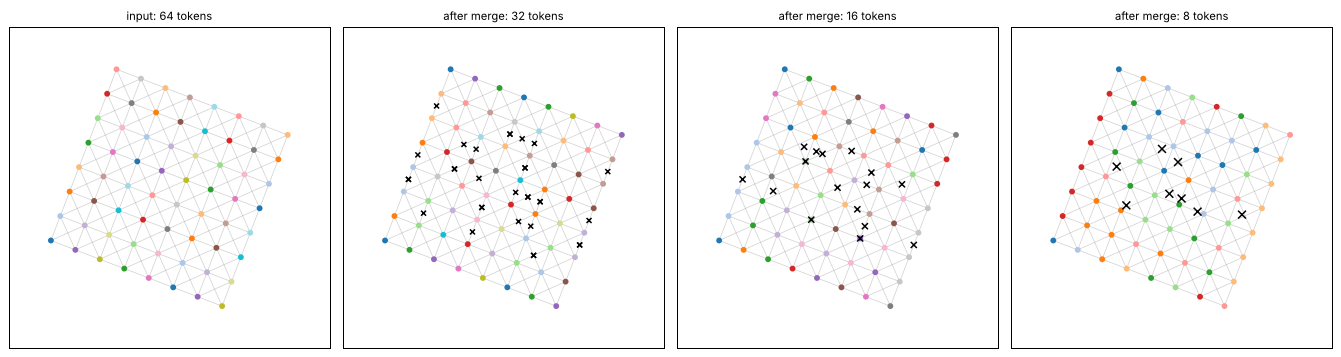

particles per super token: [8 8 8 8 8 8 8 8]


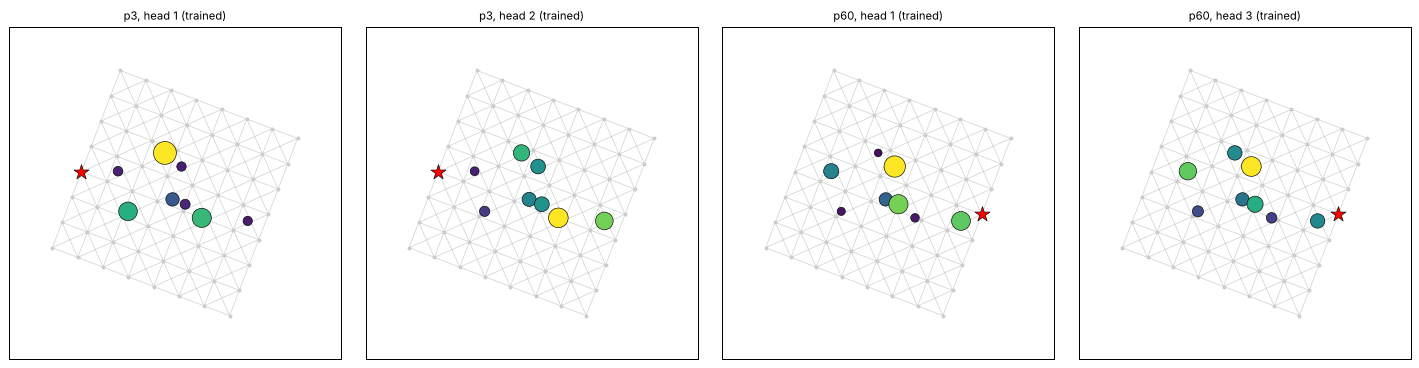

In [16]:
tr1 = trace(params_j, x_show, v_show, scene_j, norm_j, cfg=cfg)
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
viz.merge_levels(axes, xp, tr1.enc["layers"], edges)
for ax in axes:
    viz.zoom_to(ax, xp)
fig.tight_layout(); plt.show()
print("particles per super token:", np.asarray(tr1.enc["z_mult"]).astype(int))

cross1 = np.asarray(tr1.dec["layers"][0]["cross"])
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (h, p_) in zip(axes, [(0, 3), (1, 3), (0, 60), (2, 60)]):
    viz.cross_attention(ax, xp, tr1.enc["z_pos"], cross1[h, p_], p_, edges, f"p{p_}, head {h + 1} (trained)")
    viz.zoom_to(ax, xp)
fig.tight_layout(); plt.show()

The trained super tokens are **not spatial patches**. Each of the 8 groups holds 8 particles spread across the jelly,
and the anchors (crosses) all sit near the centre. Because tokens are merged by feature similarity, particles that
play the same role (on the same edge, in the same row, moving the same way) end up together, wherever they are.
Every super token holds exactly 8 particles because the pairing always joins two tokens of equal multiplicity.

The cross-attention panels: a particle (red star) spreads its attention over several super tokens. Different heads
weight them differently, and nothing here looks like "attend to the nearby region". The global stage behaves like a
small set of learned summary vectors, not a coarse mesh. This is the same kind of finding as for Transolver's slices
in [`transolver/`](../../../06-neural-operators/transolver/), where the slices were mostly fixed regions rather than
physical states.

### 8b. Are the super tokens stable over time?

One of the review's questions: merging is recomputed from scratch every frame, so do the groups jump around? We run
the trained encoder on every true frame of a test sequence and measure, for every pair of particles, whether they
share a super token. **Stability** = the fraction of pairs whose "together / apart" status is unchanged from one
frame to the next (1 = identical grouping). For reference, two independent random groupings of 64 into 8 groups of 8
agree on about 80% of pairs.

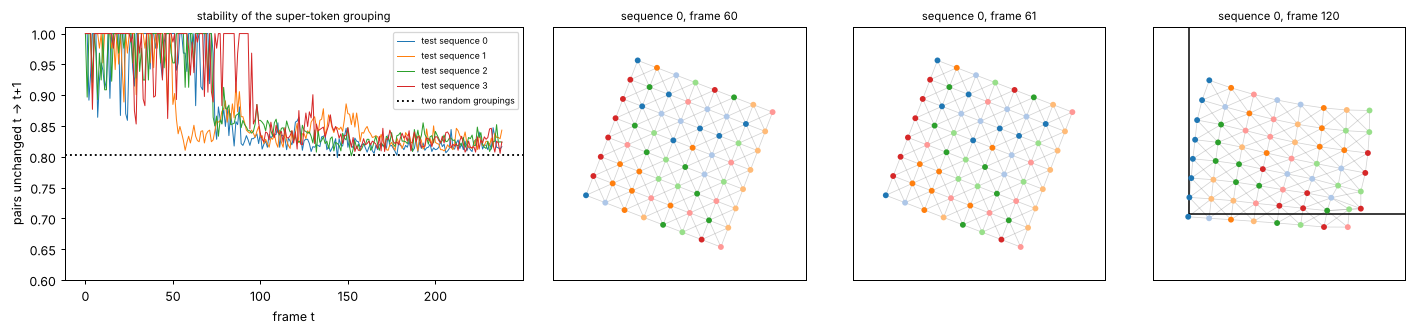

mean stability 0.876 (random: 0.802); worst frame-to-frame 0.799


In [17]:
enc_only = jax.jit(lambda x, v, sc: step_with_trace(params_j, x, v, sc, norm_j, cfg).enc["members"])
def comembership(members):
    m = np.asarray(members)
    return (m.T @ m) > 0                                  # (N, N): same super token?

seqs = range(4)
stab = []
for s_ in seqs:
    C = [comembership(enc_only(jnp.asarray(jelly_te["X"][s_, t]), jnp.asarray(jelly_te["V"][s_, t]),
                               jax.tree_util.tree_map(lambda a: a[s_], sc_te_j))) for t in range(phys.n_frames)]
    off = ~np.eye(64, dtype=bool)
    stab.append([np.mean((C[t] == C[t + 1])[off]) for t in range(phys.n_frames - 1)])
stab = np.array(stab)
rng_ = np.random.default_rng(0)
def rand_groups():
    g = rng_.permutation(np.repeat(np.arange(8), 8)); return g[:, None] == g[None, :]
rand_agree = np.mean([np.mean((rand_groups() == rand_groups())[~np.eye(64, dtype=bool)]) for _ in range(200)])

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1, 1, 1]))
for s_ in range(len(stab)):
    axes[0].plot(stab[s_], lw=0.8, label=f"test sequence {s_}")
axes[0].axhline(rand_agree, color="k", ls=":", label="two random groupings")
axes[0].set_ylim(0.6, 1.01); axes[0].set_xlabel("frame t"); axes[0].set_ylabel("pairs unchanged t -> t+1")
axes[0].legend(fontsize=7); axes[0].set_title("stability of the super-token grouping", fontsize=9)
for ax, t in zip(axes[1:], [60, 61, 120]):
    m = enc_only(jnp.asarray(jelly_te["X"][0, t]), jnp.asarray(jelly_te["V"][0, t]), scene_j)
    cols, _ = viz.token_colors(m)
    viz.particles(ax, jelly_te["X"][0, t], edges, c=cols, s=22, title=f"sequence 0, frame {t}")
    viz.zoom_to(ax, jelly_te["X"][0, t])
fig.tight_layout(); plt.show()
print(f"mean stability {stab.mean():.3f} (random: {rand_agree:.3f}); worst frame-to-frame {stab.min():.3f}")

While the jelly is in free flight (before about frame 70) the grouping is mostly stable, often identical from one
frame to the next. Once it hits the floor, the agreement drops to about 0.82, **barely above two random groupings
(0.80)**. The three panels show it: frames 60 and 61 look alike, frame 120 is reshuffled. So in this model the super
tokens flicker after contact, yet the rollout still works (section 7): the decoder does not rely on a consistent
grouping. Whether that also holds at the paper's scale is one of the questions for the authors.

## 9. Generalization

### 9a. Stiffness outside the training range

Training used $k \in [4000, 12000]$. We test $k = 3000$ (softer) and $k = 15000$ (stiffer), 8 sequences each, and
compare with fresh in-range sequences. The attribute simply goes past $\pm 1$.

### 9b. More particles

The same weights on a **10×10 jelly** (100 particles, 342 springs). Nothing in the model depends on $N$: kernels act
per neighbour, attention works for any number of tokens, and merging goes $100 \to 50 \to 25 \to 13$. The paper does
the same with 7k to 9k fluid particles (Fig. 12).

test set                          pos MSE (all frames)    at frame 100
in range, k = 6000 and 10000                  3.17e-03        1.25e-04
softer, k = 3000                              6.97e-03        1.67e-03
stiffer, k = 15000                            1.01e-02        2.26e-03
100 particles, k = 8000                       3.53e-03        3.08e-04


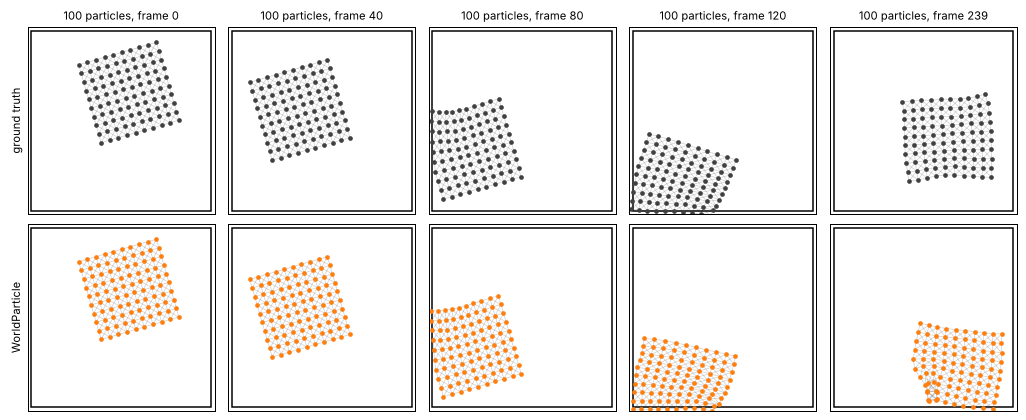

In [18]:
def jelly_eval(materials, seed, p=phys):
    d = make_dataset("jelly", len(materials), seed=seed, p=p, material=np.asarray(materials, np.float32))
    r = rollout_errors(params_j, d, stack_scenes("jelly", d["material"], p), norm_j, cfg)
    return d, r

rows_g = []
for name, mats in [("in range, k = 6000 and 10000", [6000.0] * 4 + [10000.0] * 4),
                   ("softer, k = 3000", [3000.0] * 8), ("stiffer, k = 15000", [15000.0] * 8)]:
    d_g, r_g = jelly_eval(mats, seed=20)
    rows_g.append((name, r_g["pos_mse"].mean(), r_g["pos_mse"][100]))
phys10 = phys._replace(n_side=10)
d10, r10 = jelly_eval([8000.0] * 8, seed=21, p=phys10)
rows_g.append(("100 particles, k = 8000", r10["pos_mse"].mean(), r10["pos_mse"][100]))
print(f"{'test set':32s}{'pos MSE (all frames)':>22s}{'at frame 100':>16s}")
for name, m_all, m100 in rows_g:
    print(f"{name:32s}{m_all:22.2e}{m100:16.2e}")

rest10, edges10, _ = jelly_springs(phys10)
viz.compare_frames(d10["X"][0], r10["X"][0], [0, 40, 80, 120, 239], edges10, "100 particles, "); plt.show()

* **Unseen stiffness.** Softer ($k = 3000$) is about 2× worse than in range, stiffer ($k = 15000$) about 3× worse.
  Both still bounce plausibly, but extrapolating a material parameter costs accuracy, as one would expect from a
  model that only ever saw $k \in [4000, 12000]$.
* **100 particles.** About the same error as in range, with weights trained only on 64-particle jellies. The model
  never sees $N$: kernels act on neighbours, attention and merging work for any number of tokens.

## 10. Ablation: local only

The paper's Fig. 5 removes the super tokens: a **local-only** model (tokenizer and decoder MLPs, no encoder, no
cross- or self-attention), close to Deep Lagrangian Fluids. Same data, same training budget.

step  1000   rollout loss (train batch) = 10.9918


step  2000   rollout loss (train batch) = 1.0661
local-only: 19940 parameters (full model: 62852), trained in 184 s


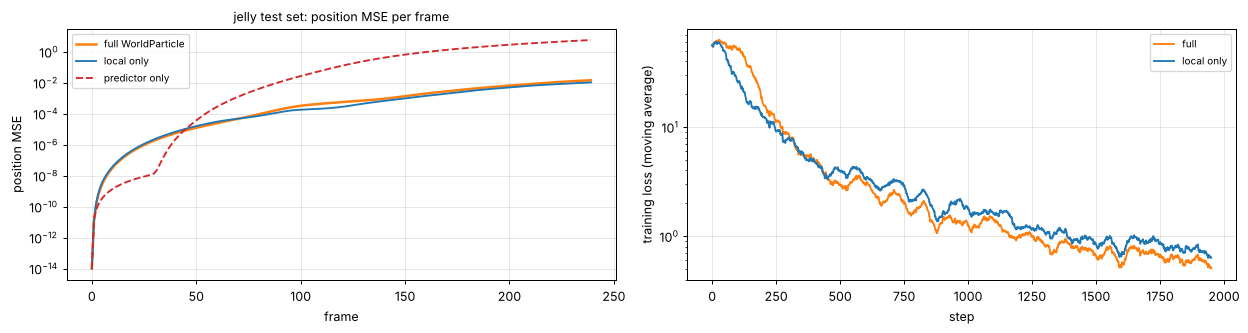

mean position MSE: full 2.62e-03, local only 1.93e-03


In [19]:
cfg_local = cfg._replace(use_global=False)
params_l0 = init_params(jax.random.PRNGKey(0), cfg_local)
t0 = time.time()
params_l, _, _, losses_l = train(params_l0, jelly_tr, sc_tr_j, norm_j, cfg_local, n_steps=2000, window=4,
                                 batch_size=8, lr=3e-3, log_every=1000)
print(f"local-only: {count_params(params_l0)} parameters (full model: {count_params(params0)}), trained in {time.time() - t0:.0f} s")
res_l = rollout_errors(params_l, jelly_te, sc_te_j, norm_j, cfg_local)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
viz.error_curves(axes[0], {"full WorldParticle": (res_j["pos_mse"], dict(c="tab:orange", lw=2)),
                           "local only": (res_l["pos_mse"], dict(c="tab:blue", lw=1.5)),
                           "predictor only": (res_pred["pos_mse"], dict(c="tab:red", ls="--"))},
                 title="jelly test set: position MSE per frame")
axes[1].semilogy(np.convolve(losses_j, np.ones(50) / 50, mode="valid"), c="tab:orange", label="full")
axes[1].semilogy(np.convolve(losses_l, np.ones(50) / 50, mode="valid"), c="tab:blue", label="local only")
axes[1].set_xlabel("step"); axes[1].set_ylabel("training loss (moving average)"); axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()
print(f"mean position MSE: full {res_j['pos_mse'].mean():.2e}, local only {res_l['pos_mse'].mean():.2e}")

**The local-only model is as good as the full one here, slightly better on average**, with a third of the parameters.
That is the opposite of the paper's fluid ablation (Fig. 5), and it is worth understanding why. Everything in this
world is local: springs act between lattice neighbours, contacts between touching grains, and one frame is only 10
solver substeps, so in one step an effect travels about one particle spacing. The paper's case for super tokens is
incompressible fluid, where pressure couples the whole tank instantly. So the value of the global stage depends on
the physics. The paper shows it only qualitatively and only for fluid, which is one of the review's points.

## 11. The sand: same architecture, other weights

Exactly the same `WPConfig`, a fresh initialisation, the sand's own data and norm. The topology inputs are zeros
(section 2), so the topology branch outputs zeros and the network learns to rely on the particle–particle and
boundary branches. This is how the paper "unifies" its six categories: one architecture, one set of weights per
category.

step   500   rollout loss (train batch) = 39.5519


step  1000   rollout loss (train batch) = 20.9860


step  1500   rollout loss (train batch) = 12.8634


step  2000   rollout loss (train batch) = 11.0673
trained in 293 s


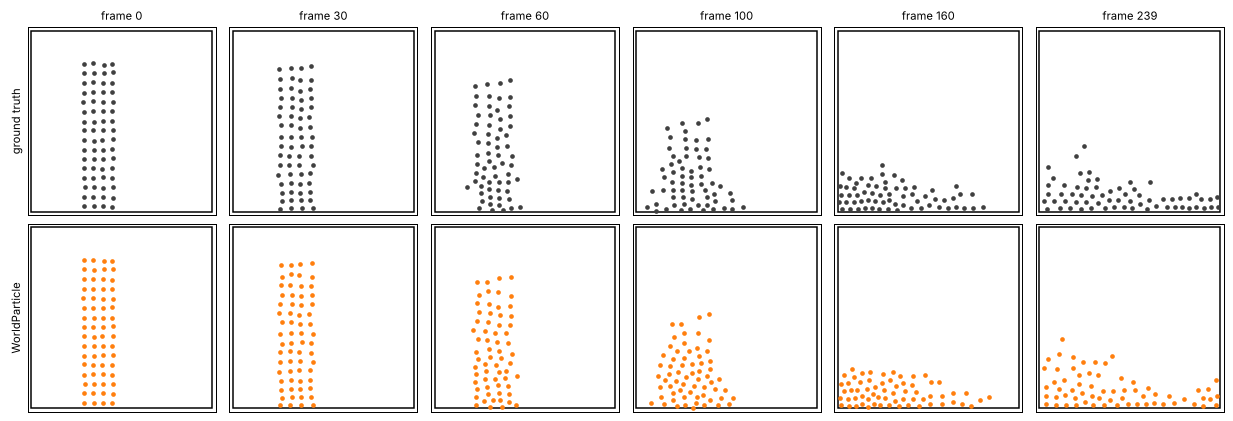

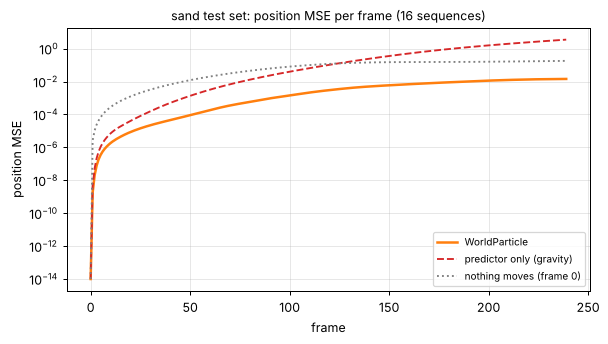

sand: mean pos MSE 4.81e-03, vel MSE 9.38e-02


In [20]:
sc_tr_s, sc_te_s = stack_scenes("sand", sand_tr["material"], phys), stack_scenes("sand", sand_te["material"], phys)
t0 = time.time()
params_s, _, _, losses_s = train(init_params(jax.random.PRNGKey(0), cfg), sand_tr, sc_tr_s, norm_s, cfg,
                                 n_steps=2000, window=4, batch_size=8, lr=3e-3, log_every=500)
print(f"trained in {time.time() - t0:.0f} s")
res_s = rollout_errors(params_s, sand_te, sc_te_s, norm_s, cfg)
res_s_pred = rollout_errors(jax.tree_util.tree_map(jnp.zeros_like, params_s), sand_te, sc_te_s, norm_s, cfg)
still_s = np.mean(np.sum((sand_te["X"] - sand_te["X"][:, :1]) ** 2, -1), axis=(0, 2))

viz.compare_frames(sand_te["X"][0], res_s["X"][0], [0, 30, 60, 100, 160, 239]); plt.show()
fig, ax = plt.subplots(figsize=(7.5, 3.8))
viz.error_curves(ax, {"WorldParticle": (res_s["pos_mse"], dict(c="tab:orange", lw=2)),
                      "predictor only (gravity)": (res_s_pred["pos_mse"], dict(c="tab:red", ls="--")),
                      "nothing moves (frame 0)": (still_s, dict(c="0.5", ls=":"))},
                 title="sand test set: position MSE per frame (16 sequences)")
plt.show()
print(f"sand: mean pos MSE {res_s['pos_mse'].mean():.2e}, vel MSE {res_s['vel_mse'].mean():.2e}")

Does the model use the friction attribute? Same initial column, two friction values, ground truth against the
model's 239-step rollout. Spread = standard deviation of the grains' $x$ at the last frame.

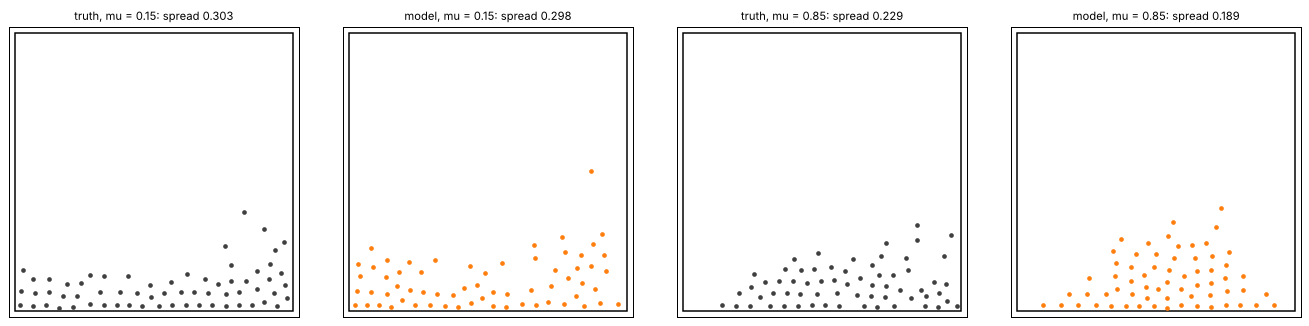

In [21]:
x0s, v0s = physics.initial_state(np.random.default_rng(11), "sand", phys)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for k, mu in enumerate([0.15, 0.85]):
    Xt, _ = physics.simulate(jnp.asarray(x0s), jnp.asarray(v0s), jnp.float32(mu), "sand", phys)
    Xm, _ = rollout(params_s, jnp.asarray(x0s), jnp.asarray(v0s), make_scene("sand", mu, phys), norm_s, cfg,
                    phys.n_frames - 1)
    Xt, Xm = np.asarray(Xt), np.asarray(Xm)
    viz.particles(axes[2 * k], Xt[-1], c="0.25", title=f"truth, mu = {mu}: spread {Xt[-1, :, 0].std():.3f}")
    viz.particles(axes[2 * k + 1], Xm[-1], c="tab:orange", title=f"model, mu = {mu}: spread {Xm[-1, :, 0].std():.3f}")
fig.tight_layout(); plt.show()

The sand is harder. Its training loss stays around 11 (the jelly's ends near 0.6). The sand's residual is dominated by
friction, a stick-slip force whose direction flips with tiny tangential velocities, and that is much harder to
predict from one frame than a spring. Still, the rollouts reproduce the collapse: the column topples and spreads into
a low pile, with a mean position MSE of about $5 \times 10^{-3}$, the same order as the jelly. The model also
**uses the friction attribute in the right direction**: more friction, less spread (truth 0.30 → 0.23, model
0.30 → 0.19). It overdoes the effect at high friction.

## 12. Interactive explorer

Pick a category, a test sequence and a frame; the left panel is the solver, the right one the model's rollout from
frame 0, coloured by the super token each particle belongs to at that frame. The sliders need a running Jupyter
kernel (press *Run Interact*). A static version is drawn below for GitHub.

In [22]:
import ipywidgets as widgets

models = {"jelly": (params_j, jelly_te, res_j, sc_te_j, norm_j, edges), "sand": (params_s, sand_te, res_s, sc_te_s, norm_s, None)}

def explore(category="jelly", sequence=0, frame=60):
    prm, data, res, scs, nrm, ed = models[category]
    sc = jax.tree_util.tree_map(lambda a: a[sequence], scs)
    xm, vm = jnp.asarray(res["X"][sequence, frame]), jnp.asarray(res["V"][sequence, frame])
    members = trace(prm, xm, vm, sc, nrm, cfg=cfg).enc["members"]
    cols, _ = viz.token_colors(members)
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
    viz.particles(axes[0], data["X"][sequence, frame], ed, c="0.25", title=f"ground truth, frame {frame}")
    viz.particles(axes[1], res["X"][sequence, frame], ed, c=cols, title="model rollout, colour = super token")
    err = np.mean(np.sum((res["X"][sequence, frame] - data["X"][sequence, frame]) ** 2, -1))
    fig.suptitle(f"{category}, test sequence {sequence}, attribute {data['material'][sequence]:.2f}, "
                 f"position MSE {err:.2e}", fontsize=10)
    fig.tight_layout(); plt.show()

widgets.interact_manual(explore, category=["jelly", "sand"], sequence=(0, 15), frame=(0, phys.n_frames - 1, 1));

interactive(children=(Dropdown(description='category', options=('jelly', 'sand'), value='jelly'), IntSlider(va…

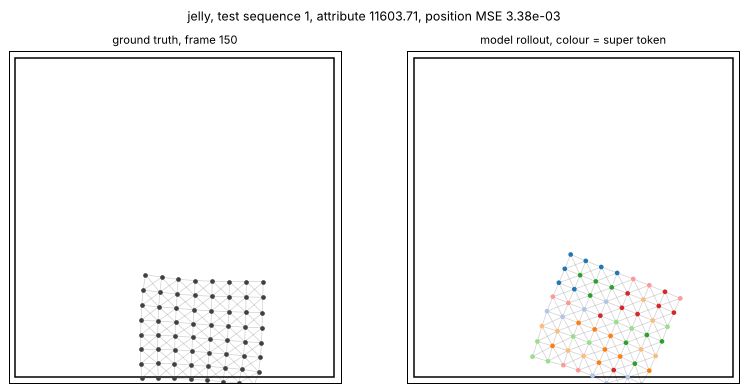

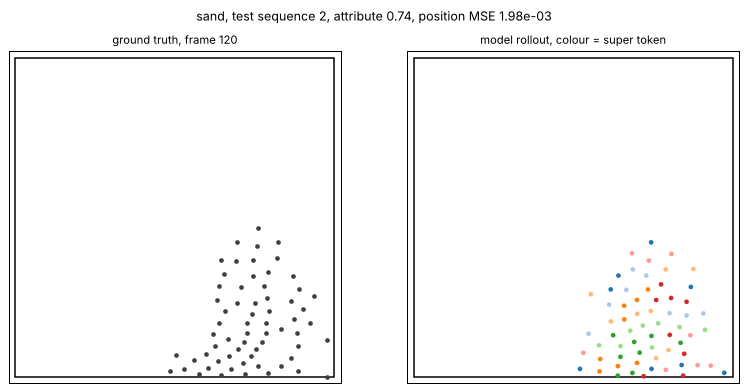

In [23]:
explore("jelly", 1, 150)
explore("sand", 2, 120)

## 13. Back to the paper and the review

What this small version shows, mapped to the claims and questions of the reviewer talk:

| paper claim or review point | what this small version shows |
| --- | --- |
| prediction–correction (Eqs. 1–2) | the predictor alone falls through the floor; the corrector keeps the jelly together and in the box (§3, §7) |
| "unified": one architecture for every category | true for the *architecture*: the jelly and the sand use identical code, with the sand's topology zero-filled. But each category gets its own weights (§11), as in the paper (Weakness 1) |
| evidence is mostly visual or averaged (Weakness 2) | a per-frame error curve is cheap to produce and tells a lot more: the error grows by orders of magnitude over a rollout, and the predictor alone wins before the first impact (§7) |
| local + global are both needed (Fig. 5) | not here: the local-only model matches the full one, because this world's physics is local (§10). The benefit of super tokens depends on the physics (Weakness 3) |
| are super tokens stable over time? (question for the authors) | not in this model: after contact the grouping is reshuffled almost as much as a random one, and the rollout still works (§8b) |
| super tokens as a coarse representation | they are feature groups spread over the body, not spatial patches (§8a) |
| generalization to unseen materials and more particles | unseen stiffness costs 2–3× in error; 100 particles instead of 64 costs nothing (§9) |

### Differences from the paper (all for size and readability)

| | WorldParticle paper | here |
| --- | --- | --- |
| dimension | 3D | 2D |
| categories | 6 (fluid, cloth, sand, non-Newtonian, elastic, protein) | 2 (jelly, sand) |
| particles | about 2k to 60k DOFs | 64 (100 in section 9b) |
| ground truth | DFSPH, GIPC, MPM, VBD, OpenMM | our own spring and contact simulators, 10 substeps per frame |
| token width, heads | 1152, 12 | 32, 4 |
| encoder / decoder layers | 6 / 8 | 3 / 2 |
| kernel lattice | $4 \times 4 \times 4$ | $4 \times 4$ |
| pair features | not fully specified | chosen so springs and contacts are linear in them (section 5b) |
| parameters | 156.7M | about 62k |
| rollout window | up to 5 | 4 |
| physics loss | optional SPH divergence (fluids) | none |
| training | 8 A100s, 400k steps, batch 1 | laptop CPU, 2000 steps, batch 8 |